# Implementation of Differentiable ODE Solvers

Library provides ordinary differential equation (ODE) solvers implemented in PyTorch. Backpropagation through ODE solutions is supported using the **adjoint method** for constant memory cost.

In [1]:
#!pip install torchdiffeq

In [2]:
import os
import argparse
import time
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
from torchdiffeq import odeint, odeint_adjoint

Supported solvers
```
SOLVERS = {
    'dopri8': Dopri8Solver,
    'dopri5': Dopri5Solver,
    'bosh3': Bosh3Solver,
    'fehlberg2': Fehlberg2,
    'adaptive_heun': AdaptiveHeunSolver,
    'euler': Euler,
    'midpoint': Midpoint,
    'heun3': Heun3,
    'rk4': RK4,
    'explicit_adams': AdamsBashforth,
    'implicit_adams': AdamsBashforthMoulton,
    # Backward compatibility: use the same name as before
    'fixed_adams': AdamsBashforthMoulton,
    # ~Backwards compatibility
    'scipy_solver': ScipyWrapperODESolver,
}

```



`rtol` Relative tolerance.

`atol` Absolute tolerance.

## A simple example

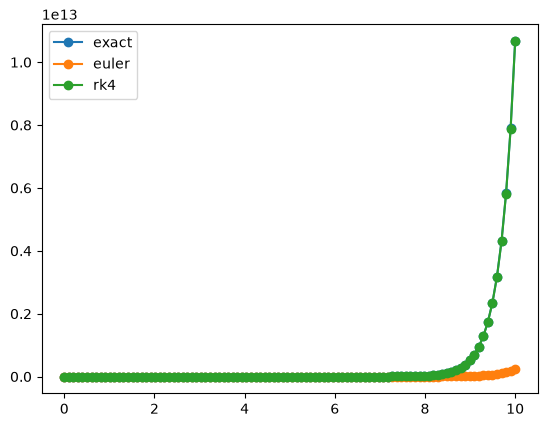

In [4]:
g = lambda t, y: 3*y

timeline = torch.linspace(0,10,100)
init=torch.tensor([1.])

exact_sol = lambda t: torch.exp(3*t) # for y(0) = 1
euler_sol = odeint(g,y0=init,t=timeline,method='euler')
rk_sol = odeint(g,y0=init,t=timeline,method='rk4')

plt.plot(timeline,exact_sol(timeline),'o-', label='exact')
plt.plot(timeline,euler_sol.detach().numpy(),'o-', label='euler')
plt.plot(timeline,rk_sol.detach().numpy(), 'o-', label='rk4')
plt.legend()


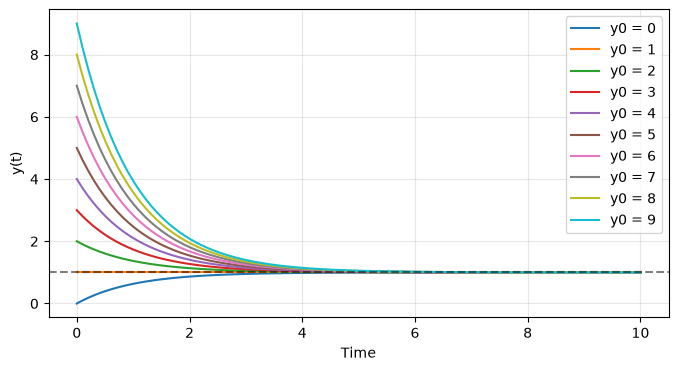

In [5]:
f = lambda t, y: 1-y

# 10 different initial conditions
y0 = torch.arange(10, dtype=torch.float32)[:, None]  # [10, 1]
t = torch.linspace(0, 10, 100)

# Integrate all trajectories simultaneously
sol = odeint(f, y0, t, method='rk4')  # [100, 10, 1]

# Plot
plt.figure(figsize=(8, 4))

for i in range(len(y0)):
    plt.plot(t.numpy(), sol[:, i, 0].detach().numpy(),
             label=f'y0 = {y0[i, 0].item():.0f}')

plt.axhline(1, color='black', linestyle='--', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('y(t)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Inverse modeling
We could used grandient-based search of the optimal parameters of a parametric ODE that fit data at best.




In [6]:
# Define the parametric ODE

class DecayODE(nn.Module):
  def __init__(self, k_init=0.2):
      super().__init__()
      self.k = nn.Parameter(torch.tensor(k_init))

  def forward(self, t, y):
      # Definition of the ODE: dy/dt = -k*y
      return -self.k * y


model = DecayODE(k_init=0.2)

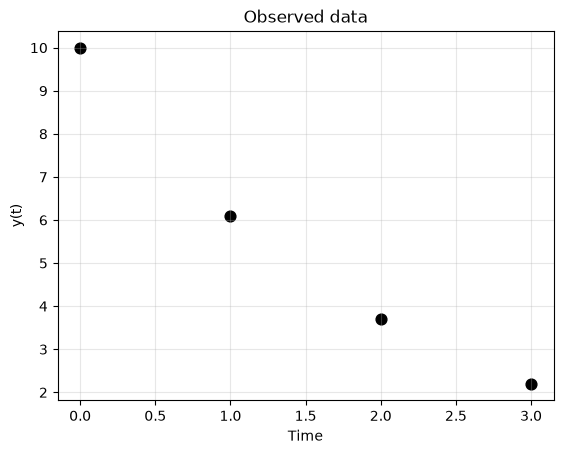

In [7]:
# Define the observations
t_obs = torch.tensor([0.0, 1.0, 2.0, 3.0])
y_obs = torch.tensor([10.0, 6.1, 3.7, 2.2])

y0 = y_obs[0]

plt.scatter(t_obs, y_obs, color="black", s=60)
plt.xlabel("Time")
plt.ylabel("y(t)")
plt.title("Observed data")
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Simulate the ODE
with torch.no_grad():
    y_initial = odeint(
        model,
        y0,
        t_obs,
        method="dopri5"
    )

print("Initial k:", model.k.item())
print("Predictions:", y_initial.numpy())

Initial k: 0.20000000298023224
Predictions: [10.        8.187293  6.7032    5.488115]


In [9]:
# Inverse modeling with gradient descent (minimize MSE)

optimizer = torch.optim.Adam(model.parameters(), lr=0.02)

loss_history = []
k_history = []

for epoch in range(300):

    optimizer.zero_grad()

    # 1. Solve the ODE with the current parameter
    y_pred = odeint(model, y0, t_obs, method="dopri5")

    # 2. Compare predictions with observations
    loss = torch.mean((y_pred - y_obs)**2)

    # 3. Compute gradients through the ODE solver
    loss.backward()

    # 4. Update the ODE parameter
    optimizer.step()

    loss_history.append(loss.item())
    k_history.append(model.k.item())

print(f"Estimated decay rate: k = {model.k.item():.4f}")

Estimated decay rate: k = 0.4988


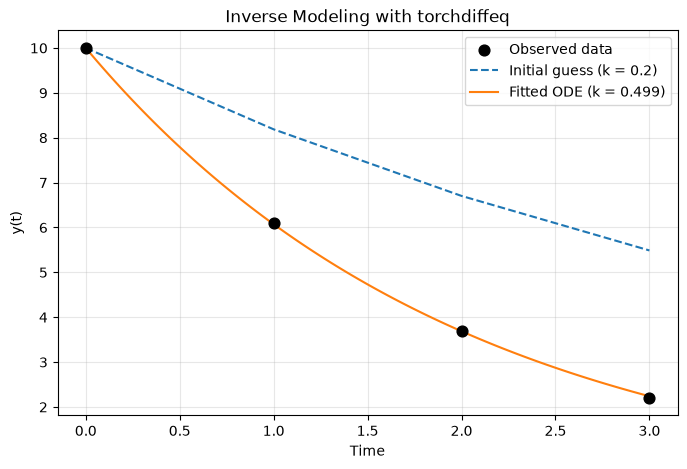

In [10]:
# Compare the fitted trajectory with the data

t_dense = torch.linspace(0, 3, 100)

with torch.no_grad():
    y_fitted = odeint(model, y0, t_dense, method="dopri5")

plt.figure(figsize=(8, 5))

plt.scatter(
    t_obs, y_obs,
    color="black", s=60,
    label="Observed data",
    zorder=3
)

plt.plot(
    t_obs, y_initial,
    "--", label="Initial guess (k = 0.2)"
)

plt.plot(
    t_dense, y_fitted,
    label=f"Fitted ODE (k = {model.k.item():.3f})"
)

plt.xlabel("Time")
plt.ylabel("y(t)")
plt.title("Inverse Modeling with torchdiffeq")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

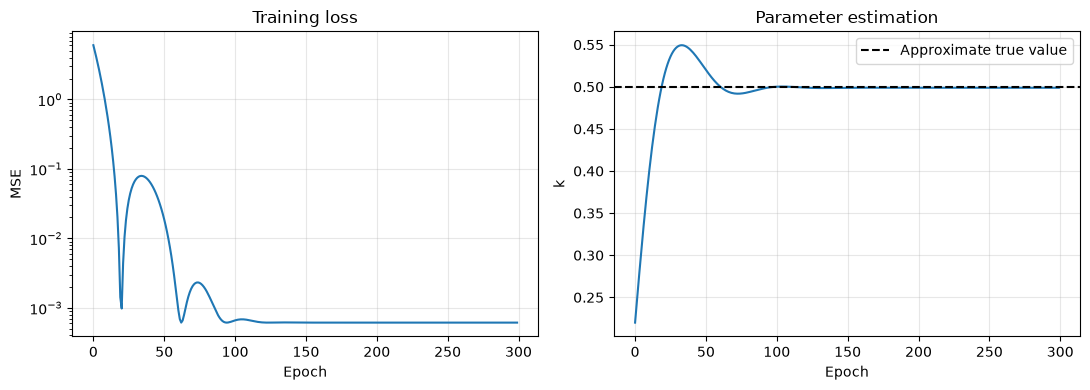

In [11]:
# Visualize the parameter optimization

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(loss_history)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_yscale("log")
axes[0].grid(alpha=0.3)

axes[1].plot(k_history)
axes[1].axhline(
    0.5,
    color="black",
    linestyle="--",
    label="Approximate true value"
)
axes[1].set_title("Parameter estimation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("k")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**MEMO:** `odeint_adjoint` must take an nn.Module as input function

Define the ODE system (dy/dt = ???)
```
class ExponentialDecayODE(torch.nn.Module):
    def forward(self, t, y):
        dydt = ???
        return dydt
```

# Differentiable event handling

`torchdiffeq` allow terminating an ODE solution based on an event function. Backpropagation through most solvers is supported.

In [12]:
from torchdiffeq import odeint_event

In [13]:
import torch
from torchdiffeq import odeint_event

# Define the ODE system (dy/dt = -2y)
class ExponentialDecayODE(torch.nn.Module):
    def forward(self, t, y):
        dydt = -2 * y
        return dydt

# Define the event function (stops integration when y < 0.1)
def event_fn(t, y):
    threshold = 0.1
    return y[0] - threshold  # Event occurs when y[0] < 0.1 (crossing zero)

# Initial parameters
y0 = torch.tensor([1.0])  # Initial condition: y(0) = 1
t0 = torch.tensor(0.)
# Solve the ODE with event handling
tevent, solution  = odeint_event(
    ExponentialDecayODE(),
    y0,
    t0,  # Start
    event_fn=event_fn,
    atol=1e-6,
    rtol=1e-6
)

# Print results
print("Solution at event:", solution)
print("Time at event:", tevent)


Solution at event: tensor([[1.0000],
        [0.1000]])
Time at event: tensor(1.1513)


Backpropagation through odeint goes through the internals of the solver. Note that this is not numerically stable for all solvers (but should probably be fine with the default dopri5 method). Instead, we encourage the use of the adjoint method, which will allow solving with as many steps as necessary due to O(1) memory usage.

In [14]:
adjoint = True
viz = True

if adjoint:
    from torchdiffeq import odeint_adjoint as odeint # to use the adjoint method
else:
    from torchdiffeq import odeint

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Simple Neural ODE

MLP as fucntion

In [15]:
class NeuralODEFunc(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 2)
        )

    def forward(self, t, z):
        return self.net(z)


model = NeuralODEFunc(hidden_dim=32)

print("Number of parameters:",
      sum(p.numel() for p in model.parameters()))

Number of parameters: 162


In [16]:
n_particles = 12

angles = torch.linspace(0, 2 * torch.pi, n_particles + 1)[:-1]

z0 = torch.stack([
    1.5 * torch.cos(angles),
    1.5 * torch.sin(angles)
], dim=1)

t = torch.linspace(0, 5, 150)

with torch.no_grad():
    solution = odeint(model, z0, t, method="dopri5")

print("Initial states:", z0.shape)       # (12, 2)
print("Solution:", solution.shape)       # (150, 12, 2)

Initial states: torch.Size([12, 2])
Solution: torch.Size([150, 12, 2])


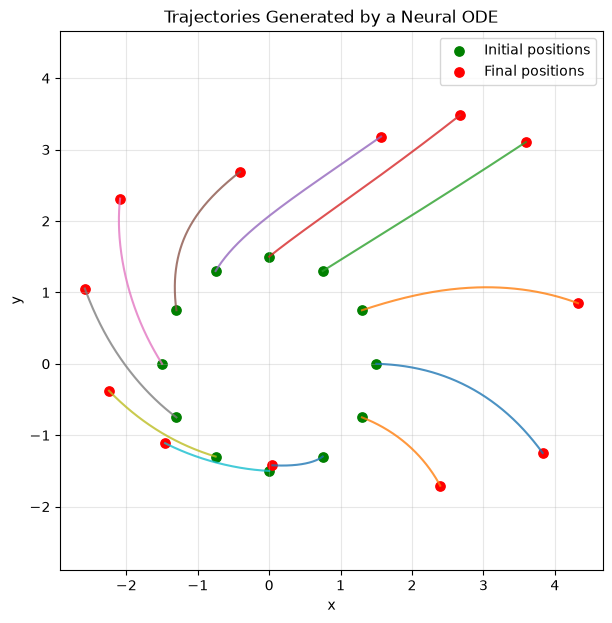

In [17]:
trajectories = solution.numpy()

plt.figure(figsize=(7, 7))

for i in range(n_particles):
    plt.plot(
        trajectories[:, i, 0],
        trajectories[:, i, 1],
        alpha=0.8
    )

plt.scatter(
    z0[:, 0], z0[:, 1],
    color="green", s=45,
    label="Initial positions"
)

plt.scatter(
    solution[-1, :, 0],
    solution[-1, :, 1],
    color="red", s=45,
    label="Final positions"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Trajectories Generated by a Neural ODE")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Training your first Neural ODE

Let's try to use a Neural ODE to capture the dynamics of

$$\frac{dy}{dt} y=-0.7y,\qquad y(0)=2.
$$

**Goal:** learn the dynamics from observed values of $y(t)$, using torchdiffeq.

In [18]:
# 1. Generate the observed trajectory
t_train = torch.linspace(0, 3, 16)
y0 = torch.tensor([2.0])

with torch.no_grad():
    y_true = 2 * torch.exp(-0.7 * t_train).unsqueeze(1)

print("Observations:", y_true.shape)  # (16, 1)

Observations: torch.Size([16, 1])


In [19]:
# 2. Neural vector field: dy/dt = f_theta(y)
class ODEFunc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Linear(1, 1, bias=False)
        with torch.no_grad():
            self.net.weight.fill_(-0.2)  # Initial (incorrect) guess

    def forward(self, t, y):
        return self.net(y)

func = ODEFunc()
print("Initial learned coefficient:", func.net.weight.item())

Initial learned coefficient: -0.20000000298023224


In [21]:
# 3. Train by comparing simulated values with observations
optimizer = torch.optim.Adam(func.parameters(), lr=0.03)
loss_history = []

for epoch in range(150):
    optimizer.zero_grad()

    y_pred = odeint_adjoint(func, y0, t_train, method="dopri5")
    loss = ((y_pred - y_true) ** 2).mean()

    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

print(f"Learned coefficient: {func.net.weight.item():.4f}  (true: -0.7)")
print(f"Final MSE: {loss_history[-1]:.6f}")

Learned coefficient: -0.7002  (true: -0.7)
Final MSE: 0.000000


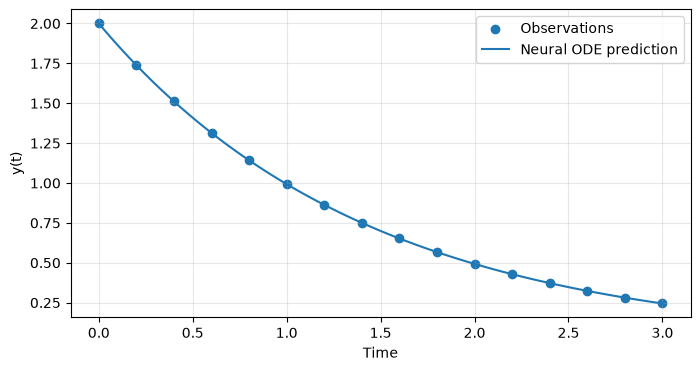

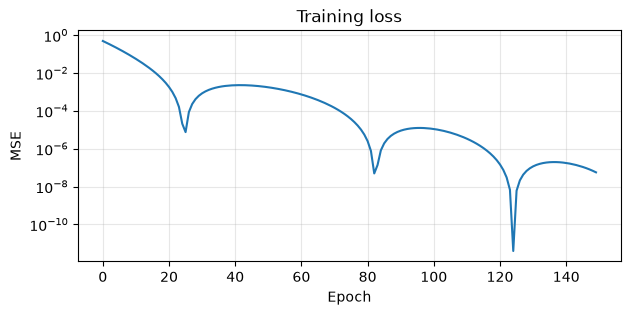

In [22]:
# 4. Compare predicted and true trajectories
t_dense = torch.linspace(0, 3, 100)

with torch.no_grad():
    y_fit = odeint(func, y0, t_dense, method="dopri5")

plt.figure(figsize=(8, 4))
plt.scatter(t_train, y_true[:, 0], label="Observations")
plt.plot(t_dense, y_fit[:, 0], label="Neural ODE prediction")
plt.xlabel("Time")
plt.ylabel("y(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training loss")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.show()

In [23]:
class ODEFuncMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, 10),
              nn.Tanh(),
              nn.Linear(10, 1)
        )

    def forward(self, t, y):
        return self.net(y)

func_mlp = ODEFuncMLP()

In [24]:
optimizer = torch.optim.Adam(func_mlp.parameters(), lr=0.03)
loss_history = []

for epoch in range(150):
    optimizer.zero_grad()

    y_pred = odeint_adjoint(func_mlp, y0, t_train, method="dopri5")
    loss = ((y_pred - y_true) ** 2).mean()

    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

print(f"Final MSE: {loss_history[-1]:.6f}")

Final MSE: 0.000071


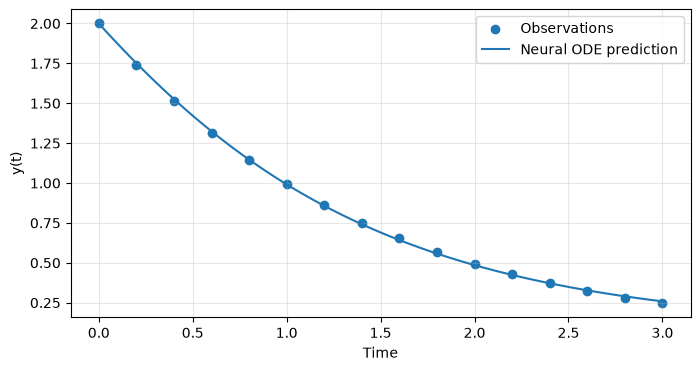

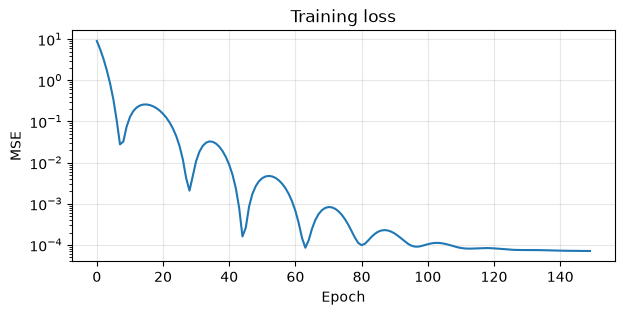

In [25]:
t_dense = torch.linspace(0, 3, 100)

with torch.no_grad():
    y_fit = odeint(func_mlp, y0, t_dense, method="dopri5")

plt.figure(figsize=(8, 4))
plt.scatter(t_train, y_true[:, 0], label="Observations")
plt.plot(t_dense, y_fit[:, 0], label="Neural ODE prediction")
plt.xlabel("Time")
plt.ylabel("y(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training loss")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.show()